In [1]:
#!pip install playsound==1.2.2


import numpy as np
import matplotlib.pyplot as plt
import librosa
import glob, os
import ipywidgets as widgets



import sys
sys.path.append(os.path.abspath("../src"))

from wavelet_utils import wavelet_denoise



In [2]:
def add_noise_snr(signal, snr_db):
    """Add Gaussian noise to a signal for a target SNR (dB)."""
    signal_power = np.mean(signal**2)
    snr_linear = 10**(snr_db / 10)
    noise_power = signal_power / snr_linear
    noise = np.random.normal(0, np.sqrt(noise_power), len(signal))
    return signal + noise

In [3]:


# --- Collect some real PCG files ---
AS_files = glob.glob("../data/train/AS/*.wav")
MR_files = glob.glob("../data/train/MR/*.wav")
MS_files = glob.glob("../data/train/MS/*.wav")
MVP_files = glob.glob("../data/train/MVP/*.wav")
Normal_files = glob.glob("../data/train/Normal/*.wav")

# Global holder for last signal
last_signal = {"t": None, "sig": None, "sr": None, "fname": None}


_last_file = None   # global tracker for file

def simulate_twin(state="Normal", noise_db=0.0, sr=2000):
    global last_signal, _last_file

    # Only pick a new file if none exists OR state changed
    if _last_file is None or last_signal["state"] != state:
        if state == "Normal":
            _last_file = np.random.choice(Normal_files)
        elif state == "AS":
            _last_file = np.random.choice(AS_files)
        elif state == "MR":
            _last_file = np.random.choice(MR_files)
        elif state == "MS":
            _last_file = np.random.choice(MS_files)
        elif state == "MVP":
            _last_file = np.random.choice(MVP_files)

    # Load original PCG (resample)
    sig, sr = librosa.load(_last_file, sr=sr)

    # Add noise based on dB
    if noise_db != 0.0:
        sig = add_noise_snr(sig, noise_db)

    # Time vector
    t = np.arange(len(sig)) / sr

    # Save globally
    last_signal = {"t": t, "sig": sig, "sr": sr, "fname": os.path.basename(_last_file), "state": state}

    return t, sig, os.path.basename(_last_file)


In [4]:
# Function to update heart based on state
def update_heart(state="Normal", noise=0.0):
    # Map state to color and text
    global status_text 

    status_text = state

In [5]:

    
# --- Extended Plot function ---
def plot_twin(state="Normal", noise=0.0):
    t, sig, fname = simulate_twin(state, noise)
    update_heart(state, noise)
    # Sampling rate from twin simulation
    sr = int(1 / (t[1] - t[0]))
    
    
    plt.figure(figsize=(10, 8), dpi=300)

    # -------------------------------
    # 1) Time-domain Waveform
    # -------------------------------
    plt.subplot(3, 1, 1)
    plt.plot(t, sig, linewidth=1.2)
    plt.title(
        f"Time-Domain PCG Waveform – Digital Twin ({state})",
        fontsize=14,
        fontweight="bold"
    )
    plt.xlabel("Time (s)", fontsize=12)
    plt.ylabel("Amplitude", fontsize=12)
    plt.tick_params(axis='both', labelsize=11)

    # -------------------------------
    # 2) FFT / Frequency Spectrum
    # -------------------------------
    plt.subplot(3, 1, 2)
    freqs = np.fft.rfftfreq(len(sig), d=1/sr)
    fft_vals = np.abs(np.fft.rfft(sig))

    plt.plot(freqs, fft_vals, linewidth=1.2)
    plt.title(
        "Frequency-Domain Representation (FFT)",
        fontsize=14,
        fontweight="bold"
    )
    plt.xlabel("Frequency (Hz)", fontsize=12)
    plt.ylabel("Magnitude", fontsize=12)
    plt.tick_params(axis='both', labelsize=11)
    plt.xlim(0, 500)  # Heart sounds mostly below 500 Hz

    # -------------------------------
    # Layout
    # -------------------------------
    plt.tight_layout(pad=2.5)

    
    

# --- Interactive dashboard ---
widgets.interact(
    plot_twin,
    state=["AS","MR", "MS","MVP", "Normal"],
    noise_db = widgets.FloatSlider(
    value=0.0,
    min=-10,
    max=10,
    step=1,
    description='Noise (dB):',
    continuous_update=False
)

)


interactive(children=(Dropdown(description='state', index=4, options=('AS', 'MR', 'MS', 'MVP', 'Normal'), valu…

<function __main__.plot_twin(state='Normal', noise=0.0)>

In [6]:
import numpy as np

signal = np.array(last_signal["sig"])   # force to numpy
sr = int(last_signal["sr"])          # samplerate must be int



import os
if os.path.exists("current_pcgSignal.wav"):
    os.remove("current_pcgSignal.wav")


In [7]:
import soundfile as sf

sf.write("current_pcgSignal.wav", signal, sr)
print("Saved current_pcgSignal.wav")

Saved current_pcgSignal.wav


In [8]:
import pygame, time

pygame.mixer.init()
pygame.mixer.music.load("current_pcgSignal.wav")
pygame.mixer.music.play()

print("Playing PCG...")
while pygame.mixer.music.get_busy():
    time.sleep(0.1)
print("Finished.")


pygame 2.6.1 (SDL 2.28.4, Python 3.11.5)
Hello from the pygame community. https://www.pygame.org/contribute.html
Playing PCG...
Finished.


In [9]:


# Stop and unload any playing music
if pygame.mixer.get_init():  
    pygame.mixer.music.stop()
    pygame.mixer.music.unload()   # <- releases the file lock


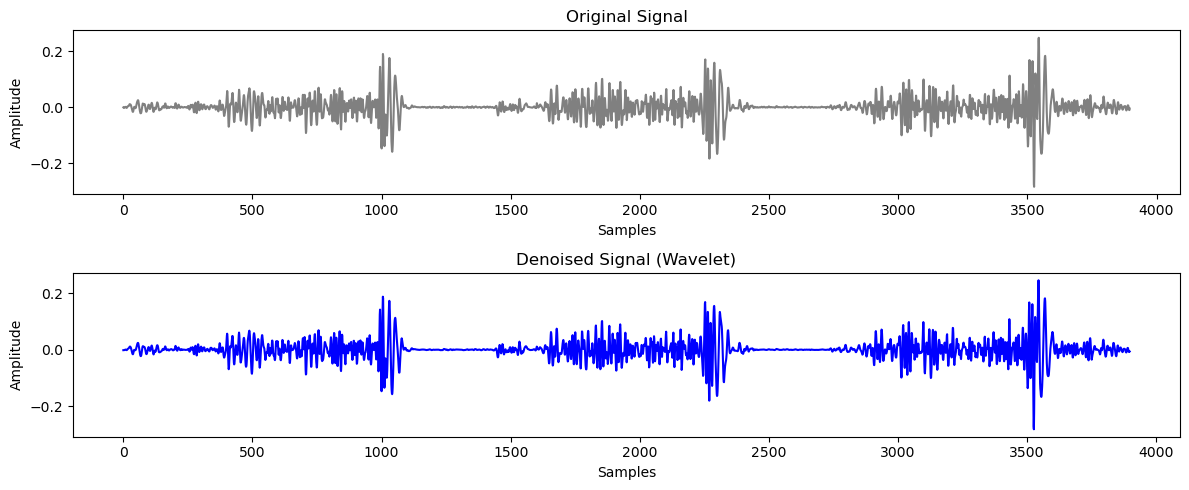

In [10]:

import numpy as np
import matplotlib.pyplot as plt
import os
import soundfile as sf   # for writing .wav



# --- Apply wavelet denoising ---
denoised_signal = wavelet_denoise(signal, wavelet="db5", level=3)


# --- Plot original vs denoised ---
plt.figure(figsize=(12,5))

plt.subplot(2,1,1)
plt.plot(signal, color="gray")
plt.title("Original Signal")
plt.xlabel("Samples")
plt.ylabel("Amplitude")

plt.subplot(2,1,2)
plt.plot(denoised_signal, color="blue")
plt.title("Denoised Signal (Wavelet)")
plt.xlabel("Samples")
plt.ylabel("Amplitude")

plt.tight_layout()
plt.show()


In [11]:
# --- Save denoised signal as WAV ---
import os
if os.path.exists("current_denoisedpcgSignal.wav"):
    os.remove("current_denoisedpcgSignal.wav")
sf.write("current_denoisedpcgSignal.wav", np.array(denoised_signal), sr)

In [12]:
import numpy as np
import time
import pygame
import trimesh
import matplotlib.pyplot as plt
from scipy.signal import hilbert
from IPython.display import display

from pythreejs import (
    BufferGeometry, BufferAttribute, Mesh, MeshStandardMaterial,
    AmbientLight, PerspectiveCamera, DirectionalLight,
    Scene, Renderer, OrbitControls
)

# =========================================================
# USER INPUTS (change per heart sound)
# =========================================================
#status_text = "Abnormal"          # "Normal" or "Abnormal"
denoised_signal = denoised_signal # your PCG signal (1D numpy array)
sr = sr                           # sampling rate
audio_path = "current_denoisedpcgSignal.wav"
obj_path = "HumanHeart_OBJ/HumanHeart.obj"

# =========================================================
# LOAD HEART MESH
# =========================================================
mesh = trimesh.load(obj_path, force='mesh')

faces_flat = mesh.faces.ravel().astype(np.uint32)
vertices = mesh.vertices.astype(np.float32)

geometry = BufferGeometry(
    attributes={
        'position': BufferAttribute(vertices),
        'index': BufferAttribute(faces_flat)
    }
)

# =========================================================
# COLOR BASED ON PCG STATE
# =========================================================
color_map = {
    "Normal": "#00ff00",
    "Abnormal": "#ff0000"
}

heart_material = MeshStandardMaterial(
    color=color_map.get(status_text, "#ff0000"),
    roughness=0.5,
    metalness=0.0
)

heart_mesh = Mesh(geometry=geometry, material=heart_material)

# Base transform
base_scale = 1.0
heart_mesh.scale = (base_scale, base_scale, base_scale)
heart_mesh.rotation = (0.2, 0.5, 0.0, "XYZ")

# =========================================================
# SCENE SETUP
# =========================================================
ambient = AmbientLight(color='#ffffff', intensity=0.7)
directional = DirectionalLight(color='#ffffff', position=[13, 5, 1], intensity=1.2)

camera = PerspectiveCamera(position=[0, 0, 25], fov=40)

scene = Scene(children=[heart_mesh, ambient, directional, camera])
controls = OrbitControls(controlling=camera, enableZoom=False)

renderer = Renderer(
    camera=camera,
    scene=scene,
    controls=[controls],
    width=600,
    height=600
)

display(renderer)

# =========================================================
# SIGNAL NORMALIZATION
# =========================================================
sig = denoised_signal.astype(np.float32)
sig /= np.max(np.abs(sig)) + 1e-8

fps = 30
duration = (len(sig) / sr) * 3
n_frames = int(duration * fps)

sig_resampled = np.interp(
    np.linspace(0, len(sig), n_frames),
    np.arange(len(sig)),
    sig
)

# =========================================================
# PHYSIOLOGICAL ENVELOPE
# =========================================================
env = np.abs(hilbert(sig_resampled))
env /= np.max(env) + 1e-8

env_smooth = np.convolve(env, np.ones(40) / 40, mode="same")

# =========================================================
# SPECTRAL FEATURES (INSTABILITY + TURBULENCE)
# =========================================================
fft_vals = np.abs(np.fft.rfft(sig))
psd = fft_vals / (np.sum(fft_vals) + 1e-8)

spec_entropy = -np.sum(psd * np.log(psd + 1e-8))
spec_entropy /= np.log(len(psd))

freqs = np.fft.rfftfreq(len(sig), 1 / sr)
hf_band = (freqs > 150) & (freqs < 400)

hf_energy = np.sum(fft_vals[hf_band])
hf_energy_norm = hf_energy / (np.sum(fft_vals) + 1e-8)

# =========================================================
# DEFORMATION MODEL
# =========================================================
contraction = 0.10 * env_smooth
instability = 0.06 * spec_entropy
turbulence = 0.05 * hf_energy_norm * np.random.randn(len(env_smooth))

sig_rescaled = (
    1.0
    + contraction
    + instability * env_smooth
    + turbulence
)

# =========================================================
# AUDIO + ANIMATION
# =========================================================
pygame.mixer.init(frequency=sr)
pygame.mixer.music.load(audio_path)
pygame.mixer.music.play(loops=1)

print("Playing PCG and animating heart...")

deformation_trace = []
frame = 0

while pygame.mixer.music.get_busy() and frame < len(sig_rescaled):
    scale_factor = sig_rescaled[frame]

    heart_mesh.scale = (
        base_scale * scale_factor,
        base_scale * scale_factor,
        base_scale * scale_factor
    )

    deformation_trace.append(scale_factor)
    frame += 1
    time.sleep(1.0 / fps)

print("Finished animation.")



D:\Installations\anaconda3\Lib\site-packages\traittypes\traittypes.py:97: UserWarning: Given trait value dtype "float32" does not match required type "float64". A coerced copy has been created.
  warnings.warn(
D:\Installations\anaconda3\Lib\site-packages\traittypes\traittypes.py:97: UserWarning: Given trait value dtype "uint32" does not match required type "float64". A coerced copy has been created.
  warnings.warn(


Renderer(camera=PerspectiveCamera(fov=40.0, position=(0.0, 0.0, 25.0), projectionMatrix=(1.0, 0.0, 0.0, 0.0, 0…

Playing PCG and animating heart...
Finished animation.


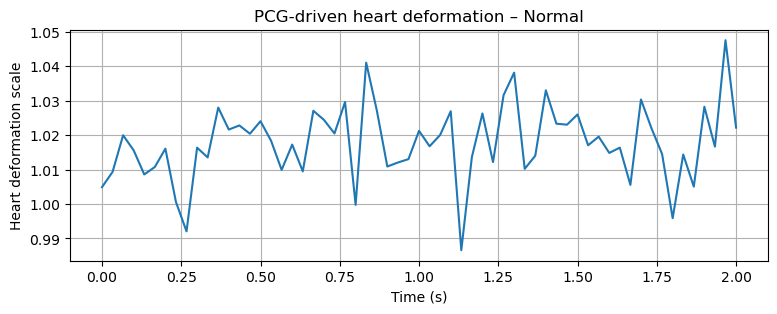


Deformation Metrics:
Mean deformation    : 1.0177
Std deviation       : 0.0109
Max expansion       : 1.0475
Min contraction     : 0.9866
Instability index   : 0.0151


In [14]:
# =========================================================
# DEFORMATION RESULTS VISUALIZATION
# =========================================================
deformation_trace = np.array(deformation_trace)
t = np.arange(len(deformation_trace)) / fps

plt.figure(figsize=(9, 3))
plt.plot(t, deformation_trace, linewidth=1.5)
plt.xlabel("Time (s)")
plt.ylabel("Heart deformation scale")
plt.title(f"PCG-driven heart deformation – {status_text}")
plt.grid(True)
plt.show()

# =========================================================
# NUMERICAL DEFORMATION METRICS
# =========================================================
metrics = {
    "Mean deformation": np.mean(deformation_trace),
    "Std deviation": np.std(deformation_trace),
    "Max expansion": np.max(deformation_trace),
    "Min contraction": np.min(deformation_trace),
    "Instability index": np.std(np.diff(deformation_trace))
}

print("\nDeformation Metrics:")
for k, v in metrics.items():
    print(f"{k:20s}: {v:.4f}")


In [15]:
if pygame.mixer.get_init():  
    pygame.mixer.music.stop()
    pygame.mixer.music.unload()  